In [3]:
import librosa
import soundfile
import zipfile
import os, glob, pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
zip_path = r"D:\speech-emotion-recognition-ravdess-data.zip"
extract_to = r"D:\RAVDESS"

if not os.path.exists(extract_to):  # Check to avoid re-extracting every time
    os.makedirs(extract_to, exist_ok=True)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)
    print("✅ RAVDESS extracted.")
else:
    print("📁 RAVDESS already extracted.")


📁 RAVDESS already extracted.


In [ ]:
emotions={
  '01':'neutral',
  '02':'calm',
  '03':'happy',
  '04':'sad',
  '05':'angry',
  '06':'fearful',
  '07':'disgust',
  '08':'surprised'
}

observed_emotions=['calm', 'happy', 'fearful', 'disgust']

In [6]:
def extract_feature(file_name, mfcc=True, chroma=True, mel=True):
    X, sample_rate = librosa.load(file_name, sr=None)
    result = np.array([])
    if chroma:
        stft = np.abs(librosa.stft(X))
    if mfcc:
        mfccs = np.mean(librosa.feature.mfcc(y=X, sr=sample_rate, n_mfcc=40).T, axis=0)
        result = np.hstack((result, mfccs))
    if chroma:
        chroma_feature = np.mean(librosa.feature.chroma_stft(S=stft, sr=sample_rate).T, axis=0)
        result = np.hstack((result, chroma_feature))
    if mel:
        mel_feature = np.mean(librosa.feature.melspectrogram(y=X, sr=sample_rate).T, axis=0)
        result = np.hstack((result, mel_feature))
    return result

In [ ]:
def load_data(test_size=0.2):
    x,y=[],[]
    for file in glob.glob(os.path.join(extract_to, "**/*.wav"), recursive=True):
        file_name=os.path.basename(file)
        emotion=emotions[file_name.split("-")[2]]
        if emotion not in observed_emotions:
            continue
        feature=extract_feature(file, mfcc=True, chroma=True, mel=True)
        x.append(feature)
        y.append(emotion)
    return train_test_split(np.array(x), y, test_size=test_size, random_state=9)

In [ ]:
x_train,x_test,y_train,y_test=load_data(test_size=0.30)

In [ ]:
print(f"Training samples: {x_train.shape[0]}, Testing samples: {x_test.shape[0]}")
print(f"Features extracted: {x_train.shape[1]}")

Training samples: 537, Testing samples: 231
Features extracted: 180


In [ ]:
model = MLPClassifier(alpha=0.01, batch_size=256, epsilon=1e-08,
                      hidden_layer_sizes=(300,), learning_rate='adaptive', max_iter=500)
model.fit(x_train, y_train)

MLPClassifier(alpha=0.01, batch_size=256, hidden_layer_sizes=(300,),
              learning_rate='adaptive', max_iter=500)

In [ ]:
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_true=y_test, y_pred=y_pred)
print("✅ Accuracy: {:.2f}%".format(accuracy * 100))

# Confusion Matrix & Classification Report
print("\n📊 Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\n📋 Classification Report:")
print(classification_report(y_test, y_pred))

✅ Accuracy: 63.20%

📊 Confusion Matrix:
[[51 17  0  1]
 [ 6 36  1 14]
 [ 5  5 24 15]
 [ 6  6  9 35]]

📋 Classification Report:
              precision    recall  f1-score   support

        calm       0.75      0.74      0.74        69
     disgust       0.56      0.63      0.60        57
     fearful       0.71      0.49      0.58        49
       happy       0.54      0.62      0.58        56

    accuracy                           0.63       231
   macro avg       0.64      0.62      0.62       231
weighted avg       0.64      0.63      0.63       231



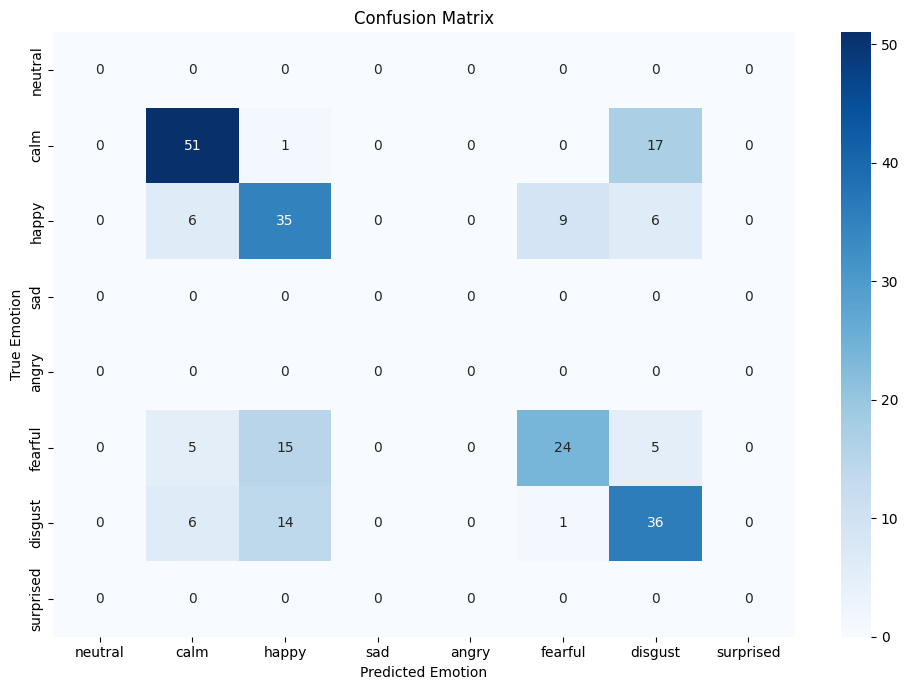

In [12]:
labels = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']

cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Emotion')
plt.ylabel('True Emotion')
plt.tight_layout()
plt.show()

In [ ]:
with open("mlp_emotion_model.pkl", "wb") as f:
    pickle.dump(model, f)
print("✅ Model saved as 'mlp_emotion_model.pkl'")

✅ Model saved as 'mlp_emotion_model.pkl'


In [ ]:
def predict_emotion(file_path):
    feature = extract_feature(file_path, mfcc=True, chroma=True, mel=True).reshape(1, -1)
    prediction = model.predict(feature)
    return prediction[0]

# Test with a new audio file
test_file = r"D:\RAVDESS\Actor_01\03-01-03-01-01-01-01.wav"
predicted = predict_emotion(test_file)
print("🎤 Predicted emotion for test file:", predicted)

🎤 Predicted emotion for test file: disgust
